In [115]:
import os
import sys
from glob import glob
import time

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# to import logger, VR-wide constants and device paths  
sys.path.append(os.path.join('.', ".."))
sys.path.append(os.path.join('..', ".."))
from baseVR.base_logger import CustomLogger as Logger
from baseVR.base_functionality import device_paths

nas_dir = device_paths()[0]


In [116]:
L = Logger()
L.init_logger(None, None, "DEBUG")

Logging at level DEBUG


In [117]:
nas_dir = device_paths()[0]
subdir = f"devices/well_devices/4983/recordings"

In [118]:
rec_dir = "2026-10-03_18.50_R=1000000_CharStim_ShowCase_large_current"
rec_dir = "2026-10-03_17.29_R=1000000_CharStim_ShowCase_large_current"
rec_dir = "2026-10-04_14.54_R=1000000_CharStim_ShowCase_large_current"
rec_dir = "2026-10-04_17.41_R=1000000_CharStim_ShowCase_large_current"
rec_dir = "2026-10-05_08.57_R=1000000_CharStim_ShowCase_large_current"

    
rec_dir = "2026-10-25_19.46_R=1024000_CharStim_ShowCase2_large_current"
# rec_dir = "2026-10-25_22.37_R=1024000_CharStim_ShowCase2_small_current"

# 1M
rec_dir = "2026-10-25_22.37_R=1024000_CharStim_ShowCase2_small_current"
# rec_dir = "2026-10-26_15.11_R=100000_CharStim_ShowCase2_small_current" # redo!

# 100k
rec_dir = "2026-10-26_17.32_R=100000_CharStim_ShowCase2_large_current"
# rec_dir = "2026-10-26_21.53_R=100000_CharStim_ShowCase2_small_current"


# load resistor in the calibration circuit [Ohm]; read from the recording name, override here if needed
import re
R_LOAD_OHM = float(re.search(r"R=(\d+)", rec_dir).group(1))

results = []
for fname in glob(os.path.join(nas_dir, subdir, rec_dir, "results_*.csv")):
    # L.info(f"Reading {fname}")
    df = pd.read_csv(fname)
    results.append(df)
results = pd.concat(results, axis=0, ignore_index=True)
results

,stimunit_id,ampl_id,set_id,DAC_val,peak_uV,peak_at,baseline,sensed_current_uA_at_peak
0,18.0,829.0,0.0,487.0,92076.0,836.0,-65374.0,-1.004144
1,18.0,829.0,0.0,489.0,80106.0,898.0,-45578.0,-0.885958
2,18.0,829.0,0.0,491.0,68136.0,843.0,-35449.0,-0.764916
3,18.0,829.0,0.0,493.0,56167.0,878.0,-28544.0,-0.641481
4,18.0,829.0,0.0,495.0,44656.0,986.0,-23479.0,-0.519443
...,...,...,...,...,...,...,...,...
1526,12.0,746.0,1.0,528.0,-28083.0,1026.0,-7366.0,0.277334
1527,12.0,746.0,1.0,530.0,-40974.0,1042.0,-5985.0,0.419990
1528,12.0,746.0,1.0,534.0,-68597.0,850.0,0.0,0.707437
1529,12.0,746.0,1.0,536.0,-80567.0,820.0,4604.0,0.847395


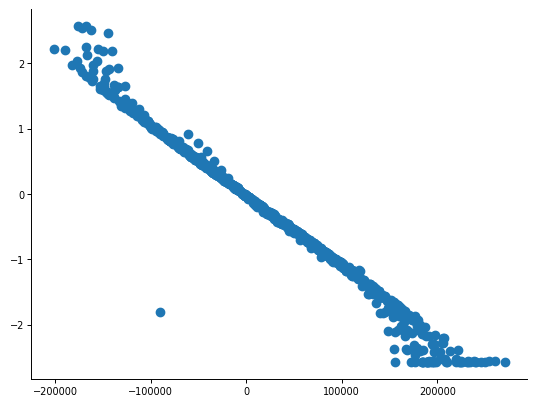

In [119]:
plt.scatter(results['peak_uV'].values, results['sensed_current_uA_at_peak'].values)

fitting 771 / 1531 points (760 outside plot window)


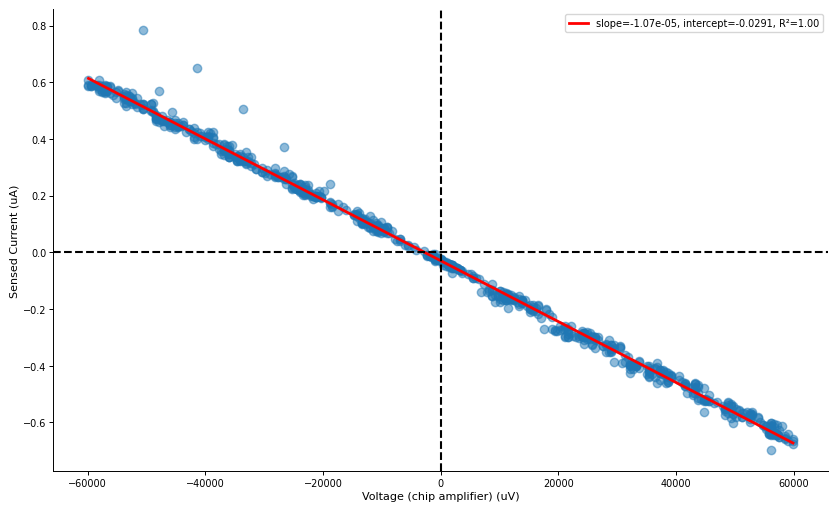

In [120]:
from sklearn.linear_model import LinearRegression

Y_SCALE = 1
fit_results = results[['peak_uV', 'sensed_current_uA_at_peak']].replace([np.inf, -np.inf], np.nan).dropna()
# keep only points inside the plotted window (both axes)
in_range = (fit_results['peak_uV'].between(-60000, 60000)
            & (fit_results['sensed_current_uA_at_peak'] * Y_SCALE).between(-20000, 20000))
print(f"fitting {in_range.sum()} / {len(in_range)} points ({(~in_range).sum()} outside plot window)")
fit_results = fit_results[in_range]

X = fit_results['peak_uV'].values.reshape(-1, 1)
y = fit_results['sensed_current_uA_at_peak'].values * Y_SCALE

reg = LinearRegression().fit(X, y)
x_line = np.linspace(X.min(), X.max(), 100).reshape(-1, 1)

plt.figure(figsize=(10, 6))
plt.scatter(X, y, alpha=0.5)
plt.plot(x_line, reg.predict(x_line), color='r', linewidth=2,
         label=f'slope={reg.coef_[0]:.3g}, intercept={reg.intercept_:.3g}, R²={reg.score(X, y):.2f}')
plt.axvline(0, color='k', linestyle='--')
plt.axhline(0, color='k', linestyle='--')
# plt.ylim(-20000, 20000)
plt.ylabel('Sensed Current (uA) * 100k, so converrted to original uV')
plt.ylabel('Sensed Current (uA)')
plt.xlabel('Voltage (chip amplifier) (uV)')
# plt.xlim(-60000, 60000)
plt.legend()

## Figure: stim-unit DAC calibration
a) circuit (load R from the recording name, `R_LOAD_OHM`), one branch per trace row of b; b) recording scheme of one sweep file: DAC command, recorded amplifier voltage and PicoScope current, aligned in time (dots = the values that enter c-e); c) DAC code → current through R (linear part of the sigmoid); d) DAC code → recorded amplifier voltage; e) voltage vs current, with the linear-regime fit that gives R; f) current LSB per stim unit: |dV/dDAC| / R from the amplifier voltage (what is available in vivo) against the slope of the PicoScope current in c. d and e share the voltage axis, c and d the DAC axis. Dashed lines: zero-current DAC code of each stim unit. One colour per stim unit, ordered by zero-crossing DAC code (`color_by="id"` orders by unit id instead).
Works for `large_current` and `small_current` recordings: set `rec_dir` in the cell that loads `results` (panel b reads the raw `.raw.h5` / `.npz` files of that recording). `make_figure` also returns a caption describing the post-processing.

In [126]:
# publication style: 7.2 in = full page width, 8 pt text, editable text in PDF/SVG
plt.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "font.size": 8, "axes.labelsize": 8, "axes.titlesize": 8,
    "xtick.labelsize": 7, "ytick.labelsize": 7, "legend.fontsize": 7,
    "axes.linewidth": 0.7, "xtick.major.width": 0.7, "ytick.major.width": 0.7,
    "xtick.major.size": 3, "ytick.major.size": 3, "xtick.major.pad": 2, "ytick.major.pad": 2,
    "axes.labelpad": 2,
    "axes.spines.top": False, "axes.spines.right": False,
    "pdf.fonttype": 42, "svg.fonttype": "none", "savefig.dpi": 300,
})

In [127]:
# panel a: calibration circuit, drawn next to the recording-scheme rows (plain matplotlib)
def _zigzag_v(ax, x, y0, y1, w=0.07, n=6, lw=1.0):
    """Vertical resistor zigzag between y0 and y1."""
    ys = np.linspace(y0, y1, 2 * n + 1)
    xs = np.r_[x, [x + (w if i % 2 else -w) for i in range(1, 2 * n)], x]
    ax.plot(xs, ys, color="k", lw=lw, solid_joinstyle="miter", clip_on=False)

def _ground(ax, x, y, lw=1.0):
    for i, hw in enumerate([0.12, 0.08, 0.04]):
        ax.plot([x - hw, x + hw], [y - i * 0.04] * 2, color="k", lw=lw, clip_on=False)

def fmt_R(R_ohm):
    return f"{R_ohm / 1e6:.3g} M$\\Omega$" if R_ohm >= 1e6 else f"{R_ohm / 1e3:.3g} k$\\Omega$"

def draw_circuit(ax, y_rows, R_ohm=None, lw=1.3, fs=8.5, label_w=0.8):
    """Stim unit / recording amplifier / ammeter, one per trace row of the scheme panel; the
    component labels at the right double as the y labels of the traces.
    ax has 1 data unit = 1 inch on both axes (set by make_figure); y_rows = row centres (inch,
    top to bottom): DAC row, voltage row, current row. The PI bus runs down the left, the
    switch sits in the stim-unit branch, GND only below the ammeter."""
    R_ohm = R_LOAD_OHM if R_ohm is None else R_ohm
    W = ax.get_xlim()[1]
    y1, y2, y3 = y_rows
    k = dict(color="k", lw=lw, solid_capstyle="round", clip_on=False)
    dot = lambda x, y: ax.add_patch(plt.Circle((x, y), 0.04, color="k", zorder=5, clip_on=False))
    x_b = 0.6                            # PI bus
    xc = W - label_w - 0.2               # centre of the stim unit / ammeter symbols
    r = 0.15
    lab = dict(ha="left", va="center", fontsize=fs, linespacing=1.15)

    # stim unit branch: bus -> switch -> current source
    sw0, sw1 = x_b + 0.3, x_b + 0.62
    ax.plot([x_b, sw0], [y1, y1], **k); ax.plot([sw1, xc - r], [y1, y1], **k)
    ax.plot([sw0, sw1 - 0.02], [y1, y1 + 0.16], **k)
    for xx in (sw0, sw1):
        dot(xx, y1)
    ax.text((sw0 + sw1) / 2, y1 + 0.2, "switch", ha="center", va="bottom", fontsize=fs - 1, color="0.35")
    ax.add_patch(plt.Circle((xc, y1), r, fill=False, lw=lw, clip_on=False))
    ax.annotate("", xy=(xc - 0.08, y1), xytext=(xc + 0.08, y1), annotation_clip=False,
                arrowprops=dict(arrowstyle="-|>", lw=lw, color="k", shrinkA=0, shrinkB=0, mutation_scale=7))
    ax.text(xc + r + 0.1, y1, "Stim. unit,\nDAC code", **lab)

    # MEA pixel electrode: short stub to the left of the top-left node
    x_e = 0.2
    ax.plot([x_e, x_b], [y1, y1], **k); dot(x_e, y1)
    ax.text(x_e - 0.1, y1 + 0.1, "MEA pixel\nelectrode", ha="left", va="bottom", fontsize=fs - 1.5,
            color="0.35", linespacing=1.0)

    # bus down to the amplifier junction, amplifier pointing at its label
    ax.plot([x_b, x_b], [y1, y3], **k)
    dot(x_b, y1); dot(x_b, y2)
    ax.text(x_b - 0.08, y2 + 0.05, "PI", ha="right", va="bottom", fontsize=fs - 1, color="0.35")
    # differential amplifier: + input on the bus, second input to its own GND
    aw, ah = 0.5, 0.36
    x_t = xc - aw / 2
    x_in = x_t - aw / 2
    yc = y2 - ah / 4                     # triangle centre; upper input level with the bus junction
    y_in2 = y2 - ah / 2
    ax.plot([x_b, x_in], [y2, y2], **k)
    ax.add_patch(plt.Polygon([[x_in, yc + ah / 2], [x_in, yc - ah / 2], [x_t + aw / 2, yc]],
                             closed=True, fill=False, lw=lw, clip_on=False))
    x_g2 = x_in - 0.2
    ax.plot([x_in, x_g2], [y_in2, y_in2], **k)
    ax.plot([x_g2, x_g2], [y_in2, y_in2 - 0.1], **k); _ground(ax, x_g2, y_in2 - 0.1, lw)
    ax.text(xc + r + 0.1, yc, "Rec. amp.\n$V$ (mV)", **lab)

    # calibration load R down the bus, then ammeter -> GND
    y_r0, y_r1 = y2 - 0.2, y3 + 0.22
    _zigzag_v(ax, x_b, y_r0, y_r1, lw=lw)
    ax.text(x_b + 0.14, (y_r0 + y_r1) / 2 - 0.12, f"$R$ = {fmt_R(R_ohm)}", ha="left", va="center", fontsize=fs - 0.5)
    ax.plot([x_b, x_b], [y3 + 0.0, y3], **k)
    ax.plot([x_b, xc - r], [y3, y3], **k); dot(x_b, y3)
    ax.add_patch(plt.Circle((xc, y3), r, fill=False, lw=lw, clip_on=False))
    ax.text(xc, y3 - 0.01, "A", ha="center", va="center", fontweight="bold", fontsize=fs - 1)
    ax.text(xc + r + 0.1, y3, "Ammeter\n$I$ ($\\mu$A)", **lab)
    ax.plot([xc, xc], [y3 - r, 0.12], **k); _ground(ax, xc, 0.12, lw)
    ax.axis("off")

In [132]:
# panel c: DAC code -> current through R, linear part of the sigmoid per stim unit
# panel d: recorded amplifier voltage vs DAC code, with its linear fit (mV / code)
# panel e: recorded voltage vs current through R, with the fit for R
# panel f: current step per DAC code of every unit, from the voltage slope and R (open: from the current)
from matplotlib.ticker import MaxNLocator

def style_axes(ax, spines=("left", "bottom"), grid="both"):
    """Light grid instead of spines; only the listed spines are kept."""
    for name, sp in ax.spines.items():
        sp.set_visible(name in spines)
    ax.set_axisbelow(True)
    ax.grid(True, axis=grid, color="0.9", lw=0.6)
    ax.tick_params(length=2.5 if spines else 0)

def robust_line(x, y, i_fit=0.8, max_res=0.2, n_iter=3):
    """Line fit on |y| < i_fit, iteratively rejecting points with |residual| > max_res."""
    keep = np.abs(y) < i_fit
    for _ in range(n_iter):
        p = np.polyfit(x[keep], y[keep], 1)
        keep = (np.abs(y) < i_fit) & (np.abs(y - np.polyval(p, x)) < max_res)
    return p

def stimunit_transfer(results, i_lin=1.0, max_res=0.2):
    """Per-stim-unit linear section of the DAC -> current transfer curve.
    Pools both readout amplifiers and all sweeps (set_id); averages per DAC code.
    Drops isolated glitch samples (> max_res uA off the robust line fit)."""
    rows, fits = [], []
    for su, g in results.groupby("stimunit_id"):
        x, y = g.DAC_val.values, g.sensed_current_uA_at_peak.values
        slope, icpt = robust_line(x, y, max_res=max_res)
        ok = (np.abs(y) < i_lin) & (np.abs(y - (slope * x + icpt)) < max_res)
        m = g[ok].groupby("DAC_val").sensed_current_uA_at_peak.agg(["mean", "std", "size"])
        rows.append(m.reset_index().assign(stimunit_id=su))
        fits.append(dict(stimunit_id=su, slope_uA_per_lsb=slope, dac0=-icpt / slope,
                         n_dropped=int(((np.abs(y) < i_lin) & ~ok).sum())))
    d = pd.concat(rows, ignore_index=True).rename(columns={"mean": "I_uA", "std": "I_std", "size": "n"})
    return d, pd.DataFrame(fits)

def plot_transfer(ax, results, cmap="viridis", i_lin=1.0, color_by="dac0", show_zero=True):
    """color_by: 'dac0' (colour ordered by zero crossing) or 'id' (by stim-unit id)."""
    d, fits = stimunit_transfer(results, i_lin)
    order = fits.sort_values("dac0" if color_by == "dac0" else "stimunit_id").stimunit_id.values
    colors = dict(zip(order, plt.get_cmap(cmap)(np.linspace(0, 0.9, len(order)))))
    for su in order:
        g = d[d.stimunit_id == su].sort_values("DAC_val")
        ax.plot(g.DAC_val, g.I_uA, color=colors[su], lw=1.0, alpha=0.9)
        ax.scatter(g.DAC_val, g.I_uA, color=colors[su], s=4, lw=0, zorder=3)
    ax.axhline(0, color="0.5", lw=0.7, zorder=1)
    if show_zero:
        ax.scatter(fits.dac0, np.zeros(len(fits)), marker="o", s=12, lw=0.5,
                   fc=[colors[s] for s in fits.stimunit_id], ec="k", zorder=5)
    ax.set_xlabel("DAC code")
    ax.set_ylabel("Current $I$ ($\\mu$A)")
    ax.set_ylim(-1.05 * i_lin, 1.05 * i_lin)
    ax.yaxis.set_major_locator(MaxNLocator(5, symmetric=True))
    ax.xaxis.set_major_locator(MaxNLocator(5))
    style_axes(ax, grid="y")
    zero_current_lines(ax, fits, colors, label=True)
    return d, fits, colors

def zero_current_lines(ax, fits, colors, label=False):
    """Faint dashed vertical line at each unit's zero-current DAC code, in the unit's colour."""
    for _, f in fits.iterrows():
        ax.axvline(f.dac0, color=colors[f.stimunit_id], lw=0.6, ls=(0, (3, 3)), alpha=0.5, zorder=0)
    if label:    # annotate once, right of the last line, where no curve runs
        ax.annotate(f"zero-current\nDAC codes", (fits.dac0.max(), -0.55), xytext=(4, 0),
                    textcoords="offset points", ha="left", va="center", fontsize=7, color="0.3",
                    linespacing=1.1)

def fit_resistance(results, fits, R_nominal_MOhm=1.0, v_frac=0.6, n_iter=3):
    """Line V = R*I + b through the linear regime of the V-I scatter (panel e): glitch samples
    removed, |V| below v_frac of the plateau (amplifier saturates beyond) and |I| below the current
    that would produce that voltage across the nominal R (excludes the plateau samples), 3 MAD
    outlier rejection. mV / uA = kOhm. Returns slope in MOhm, intercept (mV), samples, mask and r2.
    The slope is negative (V falls as I rises), report abs(R)."""
    r = results[~glitch_mask(results, fits)].dropna(subset=["sensed_current_uA_at_peak", "peak_uV"])
    I, V = r.sensed_current_uA_at_peak.values, r.peak_uV.values / 1000
    v_max = v_frac * np.percentile(np.abs(V), 90)
    window = (np.abs(V) < v_max) & (np.abs(I) < v_max / (1e3 * R_nominal_MOhm))
    keep = window
    for _ in range(n_iter):
        p = np.polyfit(I[keep], V[keep], 1)
        res = V - np.polyval(p, I)
        mad = np.median(np.abs(res[keep] - np.median(res[keep])))
        keep = window & (np.abs(res) < 3 * 1.4826 * mad)
    r2 = 1 - np.sum((V[keep] - np.polyval(p, I[keep])) ** 2) / np.sum((V[keep] - V[keep].mean()) ** 2)
    return p[0] / 1e3, p[1], I, V, keep, r2

def voltage_slopes(results, edge_frac=0.15, core=0.5, min_pts=4, n_iter=3):
    """Per stim unit: voltage step of the recording amplifier per DAC code (mV / step) in the linear
    part of the sigmoid. Median V per DAC code; the two plateaus are the medians of the outer edge_frac
    of the DAC range (robust to isolated spikes); the linear part is the contiguous run, around the
    zero crossing of a 3-point median-filtered curve, within +-core of the smaller plateau around V = 0 (widened up to 0.7 until it holds min_pts codes). Line fit on that run with 3 MAD outlier rejection.
    Needs no current measurement, so it is what is available in vivo."""
    rows = []
    for su, g in results.groupby("stimunit_id"):
        m = g.groupby("DAC_val").peak_uV.median().dropna() / 1000
        x, y = m.index.values.astype(float), m.values
        k = max(3, int(edge_frac * len(y)))
        lo_p, hi_p = np.median(y[:k]), np.median(y[-k:])
        mid, half = 0.0, min(abs(lo_p), abs(hi_p))      # V = 0 is the zero-current point (baseline subtracted)
        yp = np.r_[y[0], y, y[-1]]
        ys = np.median([yp[:-2], yp[1:-1], yp[2:]], axis=0)     # 3-point median, edges replicated
        cross = np.argmin(np.abs(ys - mid))            # point closest to the midpoint
        for c in np.arange(core, 0.71, 0.1):           # steep curves: widen until >= min_pts samples
            inside = np.abs(ys - mid) < c * half
            i0 = i1 = cross
            while i0 > 0 and inside[i0 - 1]: i0 -= 1
            while i1 < len(y) - 1 and inside[i1 + 1]: i1 += 1
            if i1 - i0 + 1 >= min_pts:
                break
        win = np.zeros(len(y), bool); win[i0:i1 + 1] = True
        keep = win
        for _ in range(n_iter):
            p = np.polyfit(x[keep], y[keep], 1)
            res = y - np.polyval(p, x)
            mad = np.median(np.abs(res[keep] - np.median(res[keep])))
            new = win & (np.abs(res) < 3 * 1.4826 * mad + 0.5)      # +0.5 mV: quantisation floor
            keep = new if new.sum() >= 3 else win
        rows.append(dict(stimunit_id=su, slope_mV_per_lsb=p[0], x_lo=x[keep].min(), x_hi=x[keep].max(),
                         icpt_mV=p[1]))
    return pd.DataFrame(rows)

def plot_voltage(ax, results, fits, colors, vs=None):
    """Recorded amplifier step (baseline-subtracted peak) vs DAC code, median per DAC code.
    Only the linear part used for the slope (vs) is drawn opaque, the rest faint."""
    ally = []
    for su in colors:
        g = results[results.stimunit_id == su]
        m = g.groupby("DAC_val").peak_uV.median() / 1000     # median: robust to the odd failed step
        ally.append(m.values)
        if vs is None:
            ax.plot(m.index, m.values, color=colors[su], lw=0.9, alpha=0.85)
            continue
        r = vs[vs.stimunit_id == su].iloc[0]
        ax.plot(m.index, m.values, color=colors[su], lw=0.7, alpha=0.35)
        lin = m[(m.index >= r.x_lo) & (m.index <= r.x_hi)]
        ax.plot(lin.index, lin.values, color=colors[su], lw=1.2, alpha=0.9, zorder=3)
        x = np.array([r.x_lo, r.x_hi])
        ax.plot(x, r.slope_mV_per_lsb * x + r.icpt_mV, color="k", lw=0.5, ls=":", zorder=4)
        ax.scatter([-r.icpt_mV / r.slope_mV_per_lsb], [0], s=12, lw=0.5, fc=[colors[su]], ec="k", zorder=5)
    ally = np.concatenate(ally)
    ax.set_ylim(1.2 * np.nanpercentile(ally, 1), 0.95 * np.nanpercentile(ally, 99))   # top spikes cropped
    ax.axhline(0, color="0.5", lw=0.7, zorder=1)
    ax.set_xlabel("DAC code")
    ax.set_ylabel("Voltage $V$ (mV)")
    ax.xaxis.set_major_locator(MaxNLocator(5))
    style_axes(ax, grid="y")

def colorscale_legend(ax, colors, label, loc=(0.15, 1.1, 0.7, 0.04)):
    """Small unlabeled viridis bar with a text label above it, in axes coords (default: above the axes)."""
    cax = ax.inset_axes(loc)
    cols = np.array(list(colors.values()))[None, :, :3]
    cax.imshow(cols, aspect="auto", interpolation="nearest")
    cax.set_xticks([]); cax.set_yticks([])
    for sp in cax.spines.values(): sp.set_visible(False)
    cax.text(0.5, 1.3, label, transform=cax.transAxes, ha="center", va="bottom")
    return cax

def glitch_mask(results, fits, i_lin=1.0, max_res=0.2):
    """True for isolated current glitch samples (same criterion as stimunit_transfer)."""
    f = fits.set_index("stimunit_id")
    sl, d0 = f.slope_uA_per_lsb.reindex(results.stimunit_id).values, f.dac0.reindex(results.stimunit_id).values
    I = results.sensed_current_uA_at_peak.values
    return (np.abs(I) < i_lin) & (np.abs(I - sl * (results.DAC_val.values - d0)) > max_res)

def plot_iv(ax, results, fits, colors, R_nominal_MOhm=1.0):
    """Recorded voltage vs current through R, all samples; emphasises the (0, 0) crossing.
    Meant to share its y axis with plot_voltage; no spines, grid only."""
    r = results[~glitch_mask(results, fits)]
    for su in colors:
        g = r[r.stimunit_id == su]
        ax.scatter(g.sensed_current_uA_at_peak, g.peak_uV / 1000, color=colors[su],
                   s=3, lw=0, alpha=0.6, rasterized=True)
    ax.axhline(0, color="0.5", lw=0.7, zorder=1)
    ax.axvline(0, color="0.5", lw=0.7, zorder=1)
    ax.scatter([0], [0], s=60, fc="none", ec="k", lw=1.0, zorder=5)
    # line through the linear regime: V = -R I + b  ->  R
    R, b, I, V, keep, r2 = fit_resistance(results, fits, R_nominal_MOhm)
    xx = np.array([I[keep].min(), I[keep].max()])
    ax.plot(xx, R * 1e3 * xx + b, color="k", lw=1.0, zorder=6)
    ax.text(0.03, 0.03, f"fit: $R$ = {fmt_R(abs(R) * 1e6)}", transform=ax.transAxes, ha="left", va="bottom",
            fontsize=6.5)
    ax.set_xlabel("Current $I$ ($\\mu$A)")
    lim = 0.1 * np.ceil(1.05 * np.nanpercentile(np.abs(r.sensed_current_uA_at_peak), 98) / 0.1)
    ax.set_xlim(-lim, lim)
    ax.xaxis.set_major_locator(MaxNLocator(3, symmetric=True))
    style_axes(ax, spines=())
    ax.tick_params(labelleft=False, left=False)
def plot_lsb(ax, fits, vs, colors, R_ohm):
    """Current step per DAC code of every stim unit. Big light circles: slope of the PicoScope current
    (c), the reference. Small dots on top: |dV/dDAC| / R_nominal from the amplifier voltage (no current
    measurement needed). mV / MOhm = nA. V/R sits a common factor k below the current (readout gain
    drops at larger voltages, see caption); k is returned and stated in the panel."""
    f, v = fits.set_index("stimunit_id"), vs.set_index("stimunit_id")
    lsb_I = f.slope_uA_per_lsb * 1e3
    lsb_V = v.slope_mV_per_lsb.abs() / (R_ohm / 1e6)
    k = float(np.median(lsb_V / lsb_I.reindex(lsb_V.index)))
    tint = lambda c: 0.55 * np.array(c[:3]) + 0.45          # opaque, lightened unit colour
    ax.scatter(lsb_I.index, lsb_I.values, s=75, fc=[tint(colors[s]) for s in lsb_I.index],
               ec="none", zorder=3, label="$I$ slope (PicoScope)")
    ax.scatter(lsb_V.index, lsb_V.values, s=16, fc=[colors[s] for s in lsb_V.index], ec="w", lw=0.4,
               zorder=4, label="$|dV/dDAC|\\,/\\,R$")
    m = lsb_I.mean()
    ax.axhline(m, color="0.4", lw=0.7, ls=(0, (3, 2)), zorder=2)
    ax.annotate(f"DAC current\nresolution\n{m:.1f} nA/code", (31.8, m), xytext=(4, 0), textcoords="offset points",
                ha="left", va="center", fontsize=6, color="0.3", annotation_clip=False, linespacing=1.1)
    ax.set_xlim(-0.8, 31.8); ax.set_xticks(range(0, 32, 2))
    ax.set_xlabel("Stim. unit"); ax.set_ylabel("LSB (nA / DAC code)")
    ax.set_ylim(0, max(lsb_I.max(), lsb_V.max()) * 1.35)
    # ax.text(0.01, 0.97, f"$V/R$ reads {100 * (1 - k):.0f} % below the measured current (see caption)",
    #         transform=ax.transAxes, ha="left", va="top", fontsize=6.5, color="0.3")
    ax.legend(frameon=False, loc="lower right", ncol=2, handlelength=1.0, fontsize=6.5, columnspacing=1.0)
    style_axes(ax, grid="y")
    return lsb_V, lsb_I, k


In [133]:
# recording scheme: DAC command, amplifier voltage and PicoScope current of single sweep files.
# MaxWell and PicoScope are not sample-synced -> the current is shifted onto the voltage per file.
from scipy.signal import butter, sosfiltfilt
from mea1k_modules.mea1k_raw_preproc import read_raw_data, read_stim_DAC

FS_KHZ = 20.0                        # MEA1K and PicoScope both stream at 20 kS/s
PICO_GAIN, R_SENSE_OHM = 100, 10_000 # sense chain, as PicoRecorder.mv_to_current_uA (picosdk not needed here)

def _lowpass(x, fc=2000.0, fs=FS_KHZ * 1e3):
    return sosfiltfilt(butter(4, fc, btype="low", fs=fs, output="sos"), x)

def _plateau_edges(s, min_amp, frac=0.5, smooth=15):
    """(first, last) sample where smoothed |s| exceeds frac of its max; None if noise only."""
    a = np.convolve(np.abs(s), np.ones(smooth) / smooth, "same")
    if a.max() < min_amp:
        return None
    idx = np.flatnonzero(a > frac * a.max())
    return idx[0], idx[-1]

def load_sweep_file(rec_path, row):
    """One DAC-sweep file. `row` is a line of results_*.csv.
    V (mV): amplifier trace minus its median over the first 500 samples. I (uA): PicoScope mV
    through the sense chain. DAC: stim DAC row. All unfiltered; *_lp copies are only for edge finding."""
    stem = f"config_StimUnit{int(row.stimunit_id):02d}_Ampl{int(row.ampl_id):04d}_Set{int(row.set_id)}_DAC{int(row.DAC_val)}"
    V = read_raw_data(rec_path, stem + ".raw.h5", convert2uV=True, row_slice=[int(row.ampl_id)])[0].astype(float)
    dac = read_stim_DAC(rec_path, stem + ".raw.h5").astype(float)
    V = (V - np.median(V[:500])) / 1000
    I = np.load(os.path.join(rec_path, stem + ".npz"))["mv"] / PICO_GAIN * 1000 / R_SENSE_OHM
    return dict(V=V, dac=dac, I=I, V_lp=_lowpass(V), I_lp=_lowpass(I), row=row)

def estimate_timing(f, min_V_mV=15, min_I_snr=8):
    """Sample indices of the connect edge in the voltage trace (v_on), of connect / disconnect in
    the PicoScope stream (i_on, i_off) and the shift of the PicoScope stream relative to the
    MaxWell stream (lag = v_on - i_on, in samples). Rising edges only: after the disconnect the
    amplifier trace keeps a slow recovery, the current plateau ends cleanly.
    Entries are None when the signal is too small to see an edge (near the zero-current code)."""
    ev = _plateau_edges(f["V_lp"], min_V_mV)
    ei = _plateau_edges(f["I_lp"] - np.median(f["I_lp"][:300]), min_I_snr * f["I"][:300].std())
    dd = np.flatnonzero(f["dac"] != f["dac"][0])
    return dict(v_on=ev[0] if ev else None, i_on=ei[0] if ei else None,
                i_off=ei[1] if ei else None,
                lag=ev[0] - ei[0] if (ev and ei) else None,
                dac_on=dd[0] if len(dd) else None, dac_off=dd[-1] if len(dd) else None,
                dac_complete=bool(len(dd) and dd[0] > 20 and dd[-1] < len(f["dac"]) - 20))

def pick_scheme_candidates(results, su, n=5, i_max=0.9, k=4):
    """For n target currents spread over the unit's +-i_max range: the k sweep files of one
    amplifier / sweep that come closest to each target."""
    g = results[results.stimunit_id == su]
    key = g.groupby(["ampl_id", "set_id"]).size().idxmax()
    g = g[(g.ampl_id == key[0]) & (g.set_id == key[1])].dropna(subset=["sensed_current_uA_at_peak"])
    g = g[g.sensed_current_uA_at_peak.abs() < i_max]
    I = g.sensed_current_uA_at_peak
    return [g.loc[(I - t).abs().sort_values().index[:k]] for t in np.linspace(I.min(), I.max(), n)]

def build_scheme(results, rec_path, su=None, n=5, i_max=0.9, k=4):
    """Aligned traces for the recording-scheme panel. Time 0 = connect edge (voltage trace); a file
    without a visible edge takes the median timing of the others. Of the k files closest to each
    target current, the one whose connected window and DAC fall are closest to the median of all
    candidates is shown, so the traces have the same length and none is cut short."""
    if su is None:   # the unit with the median zero-crossing code, a typical one
        su = results.groupby("stimunit_id").DAC_val.median().sort_values().index[results.stimunit_id.nunique() // 2]
    cands = [[load_sweep_file(rec_path, r) for _, r in c.iterrows()] for c in pick_scheme_candidates(results, su, n, i_max, k)]
    tims = [[estimate_timing(f) for f in c] for c in cands]
    med = lambda vals: np.median([v for v in vals if v is not None])
    flat = [t for c in tims for t in c]
    width = med([t["i_off"] - t["i_on"] if t["i_on"] is not None else None for t in flat])
    dac_end = med([t["dac_off"] - t["v_on"] if t["v_on"] is not None and t["dac_complete"] else None for t in flat])
    lag = med([t["lag"] for t in flat])
    on_rel_dac = med([t["v_on"] - t["dac_on"] if t["v_on"] is not None and t["dac_complete"] else None for t in flat])
    def score(t):
        s = 0 if t["dac_complete"] else 1e6
        if t["i_on"] is not None and t["dac_complete"] and t["v_on"] is not None:
            s += abs(t["i_off"] - t["i_on"] - width) + abs(t["dac_off"] - t["v_on"] - dac_end)
        return s
    out, used = [], set()
    for c, tm in zip(cands, tims):      # candidate sets of neighbouring targets overlap: never show a file twice
        sc = [score(t) + (1e9 if f["row"].DAC_val in used else 0) for f, t in zip(c, tm)]
        j = int(np.argmin(sc)); f, t = c[j], tm[j]; used.add(f["row"].DAC_val)
        v_on = t["v_on"] if t["v_on"] is not None else t["dac_on"] + on_rel_dac   # dac_on exists: file is complete
        l = t["lag"] if t["lag"] is not None else lag
        w = t["i_off"] - t["i_on"] if t["i_on"] is not None else width
        r = f["row"]
        out.append(dict(
            code=int(r.DAC_val), su=int(r.stimunit_id), lag_samples=l, lag_estimated=t["lag"] is not None,
            t=(np.arange(len(f["V"])) - v_on) / FS_KHZ, V=f["V"],
            t_dac=(np.arange(len(f["dac"])) - v_on) / FS_KHZ, dac=f["dac"],
            t_I=(np.arange(len(f["I"])) + l - v_on) / FS_KHZ, I=f["I"],
            t_off=w / FS_KHZ, t_dac_on=(t["dac_on"] - v_on) / FS_KHZ,
            t_dac_off=(t["dac_off"] - v_on) / FS_KHZ,
            # readout of the DAC-sweep csv: V at peak_at, I at the same index of the pico stream
            V_read=(r.peak_at - v_on) / FS_KHZ, V_read_val=r.peak_uV / 1000,
            I_read=(r.peak_at + l - v_on) / FS_KHZ, I_read_val=r.sensed_current_uA_at_peak))
    return out

2026-10-27 10:59:58,342|DEBUG|1931489|mea1k_raw_preproc|_get_recording_version
	Determined recording format: legacy
2026-10-27 10:59:58,342|DEBUG|1931489|mea1k_raw_preproc|_get_recording_version
	Determined recording format: legacy
2026-10-27 10:59:58,342|DEBUG|1931489|mea1k_raw_preproc|_get_recording_version
	Determined recording format: legacy
2026-10-27 10:59:58,342|DEBUG|1931489|mea1k_raw_preproc|_get_recording_version
	Determined recording format: legacy
2026-10-27 10:59:58,342|DEBUG|1931489|mea1k_raw_preproc|_get_recording_version
	Determined recording format: legacy
2026-10-27 10:59:58,342|DEBUG|1931489|mea1k_raw_preproc|_get_recording_version
	Determined recording format: legacy
2026-10-27 10:59:58,342|DEBUG|1931489|mea1k_raw_preproc|_get_recording_version
	Determined recording format: legacy
2026-10-27 10:59:58,349|DEBUG|1931489|mea1k_raw_preproc|_get_recording_version
	Determined recording format: legacy
2026-10-27 10:59:58,349|DEBUG|1931489|mea1k_raw_preproc|_get_recording_v

Calibration of the 32 stimulation units into a 100 k$\Omega$ load (64 readout amplifiers, 2 sweeps). (b) Raw traces of
five sweep files of stim. unit 26: DAC command, MEA1K amplifier voltage and PicoScope current (sense resistor 10
k$\Omega$, x100 amplifier). Amplifier voltage: baseline (median of the first 500 samples) subtracted, otherwise
unfiltered. Current: unfiltered, no offset correction. MaxWell and PicoScope are not synchronised: each current trace is
shifted onto the voltage trace by the delay between their connect edges (7.1-10.0 ms here; edge = half maximum of the
15-sample-smoothed |trace|; files without a visible edge use the median shift). t = 0 is the connect edge in the voltage
trace. Dots: values entering (c-e). Voltage = peak of the baseline-subtracted amplifier trace after a 2 kHz low-pass,
taken on the plateau after the connect transient; current = PicoScope sample at the same sample index, without the shift
above. (c) Current per DAC code, mean over amplifiers and

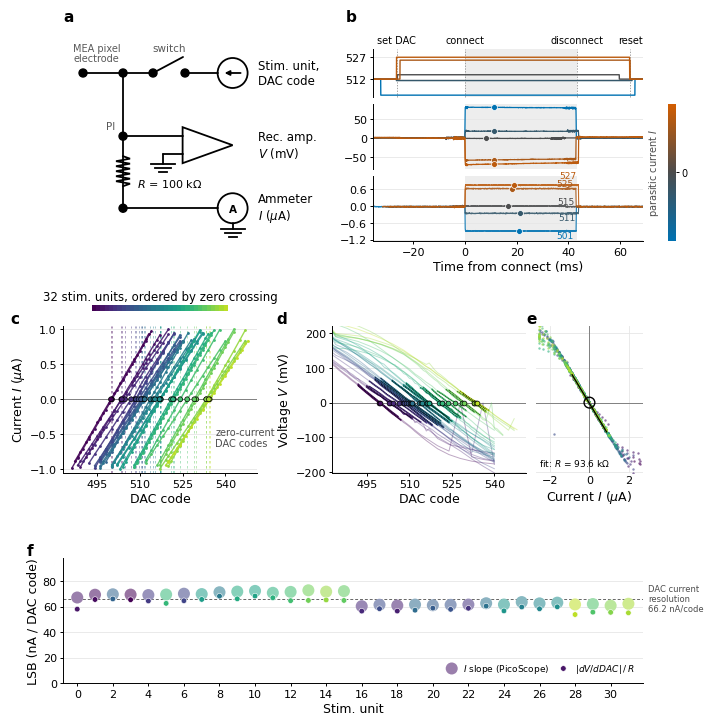

In [134]:
SCHEME_CMAP = plt.matplotlib.colors.LinearSegmentedColormap.from_list("cur", ["#0072B2", "0.3", "#D55E00"])

def plot_scheme(axes, traces):
    """DAC command / amplifier voltage / PicoScope current of a few sweep files, aligned in time.
    axes = (ax_dac, ax_v, ax_i). Colour = sign/size of the current. Dots = values that enter c-e.
    The time axis always spans the DAC rise of the earliest to the DAC fall of the latest trace."""
    ax_d, ax_v, ax_i = axes
    cur = np.array([t["I_read_val"] for t in traces])
    cols = SCHEME_CMAP(0.5 + 0.5 * cur / np.abs(cur).max())
    t_off = np.median([t["t_off"] for t in traces])
    t_dac_on = np.median([t["t_dac_on"] for t in traces])
    t_dac_off = np.median([t["t_dac_off"] for t in traces])
    t_lim = (min(t["t_dac_on"] for t in traces) - 3, max(t["t_dac_off"] for t in traces) + 3)
    for t, c in zip(traces, cols):
        ax_d.plot(t["t_dac"], t["dac"], color=c, lw=1.0)
        ax_v.plot(t["t"], t["V"], color=c, lw=0.9)
        ax_i.plot(t["t_I"], t["I"], color=c, lw=0.8, alpha=0.9)
        ax_v.scatter(t["V_read"], t["V_read_val"], s=18, color=c, ec="w", lw=0.5, zorder=5)
        ax_i.scatter(t["I_read"], t["I_read_val"], s=18, color=c, ec="w", lw=0.5, zorder=5)
    for ax in axes:
        ax.axvspan(0, t_off, color="0.93", lw=0, zorder=0)
        ax.set_xlim(*t_lim)
        style_axes(ax, spines=("left",) if ax is not ax_i else ("left", "bottom"), grid="y")
    for ax in (ax_d, ax_v):
        ax.tick_params(labelbottom=False, bottom=False)
    codes = [t["code"] for t in traces]
    ax_d.set_ylim(500, max(codes) + 0.2 * (max(codes) - 500))
    # y labels live in the circuit (panel a), next to the component that produces each trace
    ax_d.set_yticks([512] + [c for c in (min(codes), max(codes)) if abs(c - 512) > 12])
    for ax in (ax_v, ax_i):
        ax.yaxis.set_major_locator(MaxNLocator(4))
    ax_i.set_xlabel("Time from connect (ms)")
    for x, txt in [(t_dac_on, "set DAC"), (0, "connect"), (t_off, "disconnect"), (t_dac_off, "reset")]:
        ax_d.annotate(txt, (x, 1.0), xycoords=("data", "axes fraction"), xytext=(0, 3),
                      textcoords="offset points", ha="center", va="bottom", fontsize=7)
        ax_d.plot([x, x], [0, 1.0], transform=ax_d.get_xaxis_transform(), color="0.5", lw=0.5,
                  ls=(0, (2, 2)), clip_on=False, zorder=1)
    # DAC code of each trace next to its current plateau: above positive / below negative ones,
    # pushed apart where plateaus are close
    y0 = np.median([t["I"][:300].mean() for t in traces])
    sep = 0.16 * np.diff(ax_i.get_ylim())[0]
    for sign in (1, -1):
        grp = sorted([i for i, t in enumerate(traces) if np.sign(t["I_read_val"] - y0 + 1e-9) == sign],
                     key=lambda i: sign * traces[i]["I_read_val"])
        prev = None
        for i in grp:
            y = traces[i]["I_read_val"]
            y = y if prev is None else (max(y, prev + sep) if sign > 0 else min(y, prev - sep))
            ax_i.text(traces[i]["t_off"] - 1.0, y, f"{traces[i]['code']}", ha="right",
                      va="bottom" if sign > 0 else "top", fontsize=6.5, color=cols[i])
            prev = y
    lo, hi = ax_i.get_ylim(); pad = 0.12 * (hi - lo)
    ax_i.set_ylim(lo - pad, hi + pad)

def figure_caption(traces, results, fits, R_ohm, R_fit_MOhm, k):
    """Text explaining how the figure was derived from the raw recordings."""
    lags = np.array([t["lag_samples"] for t in traces if t["lag_estimated"]]) / FS_KHZ
    n_su, n_amp, n_set = results.stimunit_id.nunique(), results.ampl_id.nunique(), results.set_id.nunique()
    return (
        f"Calibration of the {n_su} stimulation units into a {fmt_R(R_ohm)} load ({n_amp} readout amplifiers, "
        f"{n_set} sweeps). (b) Raw traces of five sweep files of stim. unit {traces[0]['su']}: "
        "DAC command, MEA1K amplifier voltage and PicoScope current (sense resistor 10 k$\\Omega$, x100 amplifier). "
        "Amplifier voltage: baseline (median of the first 500 samples) subtracted, otherwise unfiltered. "
        "Current: unfiltered, no offset correction. MaxWell and PicoScope are not synchronised: each current "
        f"trace is shifted onto the voltage trace by the delay between their connect edges ({lags.min():.1f}-{lags.max():.1f} ms "
        "here; edge = half maximum of the 15-sample-smoothed |trace|; files without a visible edge use the "
        "median shift). t = 0 is the connect edge in the voltage trace. "
        "Dots: values entering (c-e). Voltage = peak of the baseline-subtracted amplifier trace after a 2 kHz "
        "low-pass, taken on the plateau after the connect transient; current = PicoScope sample at the same "
        "sample index, without the shift above. "
        "(c) Current per DAC code, mean over amplifiers and sweeps, linear section (|I| < 1 $\\mu$A); isolated samples "
        "> 0.2 $\\mu$A off a robust line fit are dropped. Dashed lines: zero crossing of that line, per unit. "
        "(d) Median voltage per DAC code, opaque in the linear part used for the fit; dotted: line fit to the linear part of the sigmoid (|V| below half the smaller "
        "plateau around the zero crossing, outliers rejected); circles: zero crossing of that fit, its slope is the "
        "voltage step per DAC code. "
        f"(e) All voltage / current pairs, glitch samples removed; line: fit in the linear regime, "
        f"R = {fmt_R(R_fit_MOhm * 1e6)} (nominal {fmt_R(R_ohm)}). "
        "(f) Current LSB per stim. unit. Large light circles: slope of the PicoScope current in (c). Small dots: "
        "|dV/dDAC| / R from the amplifier voltage and the nominal R, which needs no current measurement and is "
        f"the estimate available in vivo; dashed: mean of the current slopes, the DAC current resolution. V/R lies a common factor {k:.2f} below the "
        f"current ({100 * (1 - k):.0f} % at this R), i.e. the effective readout gain is lower than configured. "
        "The offset grows with the voltage swing: the step response compresses towards the +-180 mV plateau "
        "of the amplifier, so the slope read at |V| of up to ~100 mV (and the fit of R in (e)) falls short of the "
        "small-signal value, whereas for the 100 k$\\Omega$ load (smaller voltages) it was about 5 %. "
        "Colours in (c-f): stim. units ordered by zero-crossing DAC code.")

def make_figure(results, rec_path, su=None, R_ohm=None, color_by="dac0"):
    with plt.rc_context({"font.size": 8.5, "axes.labelsize": 9, "xtick.labelsize": 8, "ytick.labelsize": 8}):
        return _make_figure(results, rec_path, su, R_LOAD_OHM if R_ohm is None else R_ohm, color_by)

def _make_figure(results, rec_path, su, R_ohm, color_by):
    fw, fh = 7.2, 7.2
    fig = plt.figure(figsize=(fw, fh))
    gs = fig.add_gridspec(3, 1, height_ratios=[1.3, 1.0, 0.85], hspace=0.55, left=0.09, right=0.895, top=0.945, bottom=0.065)
    top = gs[0].subgridspec(1, 2, width_ratios=[1.95, 1.95], wspace=0.15)
    ax_c = fig.add_subplot(top[0])
    sch = top[1].subgridspec(3, 1, height_ratios=[0.8, 1.1, 1.1], hspace=0.12)
    ax_s = [fig.add_subplot(sch[i]) for i in range(3)]
    ax_s[1].sharex(ax_s[0]); ax_s[2].sharex(ax_s[0])
    bot = gs[1].subgridspec(1, 2, width_ratios=[1.0, 1.6], wspace=0.3)
    ax_t = fig.add_subplot(bot[0])
    vi = bot[1].subgridspec(1, 2, width_ratios=[1.0, 0.55], wspace=0.07)
    ax_v = fig.add_subplot(vi[0], sharex=ax_t); ax_iv = fig.add_subplot(vi[1], sharey=ax_v)
    ax_l = fig.add_subplot(gs[2])

    # circuit axes: 1 data unit = 1 inch, components sit at the centres of the trace rows
    pc = ax_c.get_position()
    ax_c.set_xlim(0, pc.width * fw); ax_c.set_ylim(0, pc.height * fh)
    y_rows = [(a.get_position().y0 + a.get_position().height / 2 - pc.y0) * fh for a in ax_s]
    draw_circuit(ax_c, y_rows, R_ohm)

    traces = build_scheme(results, rec_path, su=su)
    plot_scheme(ax_s, traces)
    # trace colour = current: vertical colour bar right of b, 0 ticked, label on the other side
    fig.canvas.draw()
    p1, p2 = ax_s[1].get_position(), ax_s[2].get_position()
    cb = fig.add_axes([p1.x1 + 0.035, p2.y0, 0.011, p1.y1 - p2.y0])
    cb.imshow(SCHEME_CMAP(np.linspace(1, 0, 256))[:, None, :3], aspect="auto", extent=(0, 1, -1, 1))
    cb.set_xticks([]); cb.yaxis.tick_right(); cb.set_yticks([0]); cb.set_yticklabels(["0"], fontsize=7)
    cb.tick_params(length=2.5, pad=1.5)
    for sp in cb.spines.values(): sp.set_visible(False)
    cb.text(-0.9, 0.5, "parasitic current $I$", transform=cb.transAxes, rotation=90, ha="right", va="center", fontsize=7, color="0.3")
    d, fits, colors = plot_transfer(ax_t, results, color_by=color_by)
    xlim = ax_t.get_xlim()
    colorscale_legend(ax_t, colors, f"{len(colors)} stim. units, ordered by zero crossing" if color_by == "dac0" else f"stim. unit 0 $\\rightarrow$ {len(colors) - 1}")
    vs = voltage_slopes(results)
    plot_voltage(ax_v, results, fits, colors, vs)
    ax_v.set_xlim(*xlim)
    plot_iv(ax_iv, results, fits, colors, R_ohm / 1e6)
    _, _, k = plot_lsb(ax_l, fits, vs, colors, R_ohm)

    fig.canvas.draw()
    top_y = ax_s[0].get_position().y1 + 0.035
    for ax, l in [(ax_c, "a"), (ax_s[0], "b"), (ax_t, "c"), (ax_v, "d"), (ax_iv, "e"), (ax_l, "f")]:
        bb = ax.get_tightbbox(fig.canvas.get_renderer()).transformed(fig.transFigure.inverted())
        x = ax_iv.get_position().x0 if ax is ax_iv else max(bb.x0, 0.004)
        y = top_y if ax in (ax_c, ax_s[0]) else ax.get_position().y1
        fig.text(x, y, l, fontweight="bold", fontsize=11, va="bottom", ha="right" if ax is ax_iv else "left")
    R_fit = abs(fit_resistance(results, fits, R_ohm / 1e6)[0])
    return fig, fits, colors, figure_caption(traces, results, fits, R_ohm, R_fit, k)

fig, fits, colors, caption = make_figure(results, os.path.join(nas_dir, subdir, rec_dir))
# fig.savefig(os.path.join(nas_dir, subdir, rec_dir, "fig_DAC_calibr.pdf"), bbox_inches="tight")
import textwrap
print(textwrap.fill(caption, 120))
print(fits.describe().loc[["mean", "std", "min", "max"], ["slope_uA_per_lsb", "dac0"]])
print("dropped glitch samples:\n", fits[fits.n_dropped > 0])

## LSB sines: paired voltage (MEA1K amplifier) and current (PicoScope)
±3 DAC codes around the zero-current code at 1 kHz. Values come from `processed/large_current_lsb_characterization.csv`, written live by `char_current_lsb` (lock-in amplitudes per recording; MaxWell and PicoScope are not sample-synced, so no cycle-by-cycle I–V). For raw traces see `live_figures/debug_amplifier.png` / `debug_picoscope_signal.png`.
Per stim unit: grey line separates the stim-unit banks 0–15 / 16–31, dashed lines are bank means.

In [ ]:
# per stim unit: current, voltage, V/I and LSB (from I vs from V/R), from the eval csv
def load_lsb_results(rec_path, stim_mode="large_current", conditions=None, sweep_subdir="LSB_sweep"):
    """Per-recording sine LSB results. Reads <rec_path>/LSB_sweep (char_current_lsb_sweep, several
    gains/frequencies) if it exists, else the single-condition csv of char_current_lsb in processed/.
    conditions: None for all, or {column: value or list of values} to subset, e.g.
    {"gain": 7, "freq": [10, 1000]}."""
    sweep_csv = os.path.join(rec_path, sweep_subdir, "processed", f"{stim_mode}_lsb_sweep.csv")
    if os.path.exists(sweep_csv):
        d = pd.read_csv(sweep_csv)
    else:
        d = pd.read_csv(os.path.join(rec_path, "processed", f"{stim_mode}_lsb_characterization.csv"))
    for col, vals in (conditions or {}).items():
        d = d[d[col].isin(np.atleast_1d(vals))]
    if d.empty:
        raise ValueError(f"No recordings left for conditions={conditions}")
    d = d.copy()
    d["V_mV"] = d.mean_amplitude_uV / 1000
    d["I_uA"] = d.external_current_uA
    d["R_eff_MOhm"] = d.V_mV / d.I_uA / 1000
    d["LSB_I_nA"] = d[f"{stim_mode}_external_LSB_nA"]
    d["LSB_V_nA"] = d[f"{stim_mode}_LSB_nA"]           # V / R, R from the csv
    return d

def _per_su(ax, d, col, colors, jitter=0.18, s=5, marker="o", fc=True, med_color="k", label=None):
    """Recordings as jittered dots per stim unit + median bar."""
    rng = np.random.default_rng(0)
    for su, g in d.groupby("stimunit_id"):
        c = colors.get(su, "k")
        x = su + rng.uniform(-jitter, jitter, len(g))
        ax.scatter(x, g[col], s=s, marker=marker, lw=0.5, alpha=0.8,
                   fc=c if fc else "none", ec=c if not fc else "none", zorder=3)
        ax.plot([su - 0.35, su + 0.35], [g[col].median()] * 2, color=med_color, lw=1.0, zorder=4,
                label=label if su == d.stimunit_id.min() else None)

def _bank_means(ax, d, col, split=16, fmt="{:.3f}"):
    """Mean per stim-unit bank (0-15, 16-31) as a thin line + value."""
    for lo, hi in [(0, split - 1), (split, d.stimunit_id.max())]:
        m = d[d.stimunit_id.between(lo, hi)][col].mean()
        ax.plot([lo - 0.5, hi + 0.5], [m, m], color="0.4", lw=0.6, ls=(0, (3, 2)), zorder=2)
        # value label above the line, at the right end of each bank
        ax.annotate(fmt.format(m), (hi + 0.4, m), xytext=(0, 1.5), textcoords="offset points",
                    ha="right", va="bottom", fontsize=6, color="0.3", zorder=5,
                    bbox=dict(fc="w", ec="none", pad=0.3, alpha=0.8))

def plot_lsb_per_stimunit(axes, d, colors, split=16):
    ax_i, ax_v, ax_r, ax_l = axes
    _per_su(ax_i, d, "I_uA", colors); _bank_means(ax_i, d, "I_uA")
    ax_i.set_ylabel("$I$ amp.\n($\\mu$A)")
    _per_su(ax_v, d, "V_mV", colors); _bank_means(ax_v, d, "V_mV", fmt="{:.0f}")
    ax_v.set_ylabel("$V$ amp.\n(mV)")
    _per_su(ax_r, d, "R_eff_MOhm", colors); _bank_means(ax_r, d, "R_eff_MOhm", fmt="{:.2f}")
    R = d.resistance.iloc[0] / 1e6
    ax_r.axhline(R, color="k", lw=0.8, ls=(0, (3, 2)))
    ax_r.annotate(f"$R$ = {R:.3f} M$\\Omega$", (0, R), xytext=(0, -1.5), textcoords="offset points",
                  ha="left", va="top", fontsize=6)
    ax_r.set_ylabel("$V/I$\n(M$\\Omega$)")
    ax_r.set_ylim(min(0.75, d.R_eff_MOhm.min() - 0.02), R + 0.05)
    _per_su(ax_l, d, "LSB_I_nA", colors, label="from $I$")
    _per_su(ax_l, d, "LSB_V_nA", colors, marker="o", fc=False, med_color="0.5", label="from $V/R$")
    ax_l.set_ylabel("LSB\n(nA/code)")
    ax_l.legend(frameon=False, loc="upper right", ncol=2, handlelength=1.2, fontsize=6)
    for ax in axes:
        ax.axvline(split - 0.5, color="0.6", lw=0.6, zorder=0)
        ax.set_xlim(-0.8, d.stimunit_id.max() + 0.8)
    for ax in axes[:-1]:
        ax.tick_params(labelbottom=False)
    ax_l.set_xticks(range(0, int(d.stimunit_id.max()) + 1, 2))
    ax_l.set_xlabel("Stim. unit")

def plot_lsb_conditions(d, colors, group_cols=("gain", "freq")):
    """One figure per condition (gain, frequency), all recordings of one condition per figure.
    Old single-condition csvs have no gain column -> one figure."""
    group_cols = [c for c in group_cols if c in d and d[c].notna().any()]
    groups = d.groupby(group_cols) if group_cols else [((), d)]
    figs = []
    for key, g in groups:
        key = key if isinstance(key, tuple) else (key,)
        fig, axes = plt.subplots(4, 1, figsize=(7.2, 3.8), sharex=True, gridspec_kw=dict(hspace=0.12))
        plot_lsb_per_stimunit(axes, g, colors)
        fig.align_ylabels(axes)
        if group_cols:
            fig.suptitle(", ".join(f"{c} = {v:g}" for c, v in zip(group_cols, key)), fontsize=8)
        figs.append(fig)
    return figs


In [ ]:
lsb_path = os.path.join(nas_dir, subdir, rec_dir)
# all conditions of LSB_sweep (one figure each), or a subset, e.g. {"gain": 7, "freq": [10, 1000]}
conditions = {"gain": 7, "freq": [10, 1000]}
# lsb = load_lsb_results(lsb_path, stim_mode="large_current", conditions=conditions)
lsb = load_lsb_results(lsb_path, stim_mode="small_current", conditions=conditions)
figs = plot_lsb_conditions(lsb, colors)

bank = np.where(lsb.stimunit_id < 16, "SU 0-15", "SU 16-31")
cond_cols = [c for c in ("gain", "freq") if c in lsb and lsb[c].notna().any()]
lsb.groupby(cond_cols + [bank])[["I_uA", "V_mV", "R_eff_MOhm", "LSB_I_nA", "LSB_V_nA", "phase_shift_deg"]].agg(["mean", "std"]).round(3)

In [ ]:
def plot_sine_iv(ax, d, colors):
    """V vs I sine amplitude per recording; lines through the origin for fitted and nominal R."""
    R = d.resistance.iloc[0]
    for su, g in d.groupby("stimunit_id"):
        ax.scatter(g.I_uA, g.V_mV, color=colors.get(su, "k"), s=10, lw=0.3, ec="w", zorder=3)
    r_fit = np.median(d.R_eff_MOhm)
    x = np.array([0, d.I_uA.max() * 1.1])
    ax.plot(x, x * R / 1e3, color="0.5", lw=0.8, ls=(0, (3, 2)), label=f"$R$ = {R/1e6:.3f} M$\\Omega$")
    ax.plot(x, x * r_fit * 1e3, color="k", lw=0.9, label=f"fit: {r_fit:.2f} M$\\Omega$")
    ax.scatter([0], [0], s=40, fc="none", ec="k", lw=1.0, zorder=5)
    ax.set_xlim(0, x[1]); ax.set_ylim(0, x[1] * R / 1e3)
    ax.set_xlabel("Current amplitude $I$ ($\\mu$A)")
    ax.set_ylabel("Voltage amplitude $V$ (mV)")
    ax.legend(frameon=False, loc="upper left", handlelength=1.5)

# colors comes from the DAC-sweep figure above (same stim-unit colour code)
fig, ax = plt.subplots(figsize=(2.4, 2.1))
plot_sine_iv(ax, lsb, colors)

## Is the MEA1K gain really 7?

A known 1 kHz sine delivered to the chip **in saline**, recorded with `gain = 7`.
Saline shorts every electrode to the same bath potential, so all 1012 routed
amplifiers see the *same* voltage: the spread across channels is the
amplifier-to-amplifier gain variation, and the median is the readout scale.

This needs no current source, no calibration load and no PicoScope. It does depend
on knowing the amplitude that actually reached the electrode -- set `applied_mV`
below; every absolute number scales linearly with it, while the *linearity* check
(50 mV vs 10 mV) and the channel spread do not depend on it at all.

In [ ]:
# --- external 1 kHz sine recordings: loading -------------------------------------
import h5py
from scipy.signal import butter, filtfilt

# MaxLab GUI "Trace_*" files use the legacy layout and MaxWell's own HDF5 compression
# filter. Without this the read fails with "can't open directory .../hdf5/plugin".
os.environ.setdefault("HDF5_PLUGIN_PATH", "/usr/local/hdf5/lib/plugin")

EXT_DIR = os.path.expanduser("~/Data/recordings")
EXT_FREQ = 1000.0
ADC_CENTRE = 512                      # ephys_constants.ADC_RESOLUTION / 2

# applied_mV = sine AMPLITUDE (not Vpp) at the electrode.
# NOTE: these are the generator's front-panel settings, not a measured value. If the
# generator was set in Vpp, or terminated into 50 Ohm while driving a high-Z load,
# the true amplitude differs by 2x -- correct it here and every absolute number below
# follows.
EXT_RECORDINGS = {
    "50 mV": dict(fname="Trace_20261010_18_42_06_50mV_Gain7.raw.h5", applied_mV=50.0),
    "10 mV": dict(fname="Trace_20261010_18_42_06_10mV_Gain7.raw.h5.raw.h5", applied_mV=10.0),
}

# scale factor the stim-unit chain probe measured, flat over 100-2000 Hz
# (2026-10-10_13.25_..._ChainProbeFreqSweep, V_mea1k / V_pico)
STIM_SCALE = 0.849
NOMINAL_GAIN = 7.0


def read_legacy_mea1k(fullfname):
    """Routed raw data of a MaxLab GUI trace -> (mV per channel, fs, gain, lsb_uV).

    Converts with the file's OWN lsb rather than the ephys_constants override, so this
    analysis cannot be circular: it must be able to disagree with the assumed gain.
    """
    with h5py.File(fullfname, "r") as h:
        b = "data_store/data0000/"
        gain = float(h[b + "settings/gain"][0])
        lsb_uV = float(h[b + "settings/lsb"][0]) * 1e6
        fs = float(h[b + "settings/sampling"][0])
        raw = h[b + "groups/routed/raw"][:, :]
    x = (raw.astype(np.float64) - ADC_CENTRE) * lsb_uV / 1000.0        # mV
    return x - x.mean(axis=1, keepdims=True), fs, gain, lsb_uV


def sine_amplitude(x, freq, fs, half_band=50.0, edge=400):
    """Per-channel amplitude of a sine at `freq`: sqrt(2) x std of a narrow bandpass.

    Model-free on purpose. A single-FFT-bin amplitude is biased low when the peak
    falls between bins (Hann scalloping, up to 15%) and a fixed-reference lock-in
    picks up whatever noise sits inside its band; neither affects this estimator.
    """
    b, a = butter(4, [(freq - half_band) / (fs / 2), (freq + half_band) / (fs / 2)],
                  btype="band")
    return filtfilt(b, a, np.atleast_2d(x), axis=1)[:, edge:-edge].std(axis=1) * np.sqrt(2)


def dominant_freq(x, fs, fmin=20.0):
    """Strongest spectral component of the channel-average, to verify the drive."""
    n = x.shape[1]
    spec = np.abs(np.fft.rfft(x * np.hanning(n), axis=1)).mean(0)
    fr = np.fft.rfftfreq(n, 1 / fs)
    return float(fr[np.argmax(np.where(fr > fmin, spec, 0))])


In [ ]:
# --- external 1 kHz sine recordings: per-channel amplitude -----------------------
ext = {}
for label, cfg in EXT_RECORDINGS.items():
    x, fs, gain, lsb_uV = read_legacy_mea1k(os.path.join(EXT_DIR, cfg["fname"]))
    A = sine_amplitude(x, EXT_FREQ, fs)
    ext[label] = dict(A=A, fs=fs, gain=gain, lsb_uV=lsb_uV,
                      f_drive=dominant_freq(x, fs), n_ch=x.shape[0], **cfg)

rows = []
for label, e in ext.items():
    med = np.median(e["A"])
    q1, q3 = np.percentile(e["A"], [25, 75])
    rows.append({
        "recording": label, "applied_mV": e["applied_mV"], "f_drive_Hz": e["f_drive"],
        "n_channels": e["n_ch"], "file_gain": e["gain"], "lsb_uV": round(e["lsb_uV"], 2),
        "measured_mV": med, "IQR_mV": q3 - q1, "spread_pct": 100 * (q3 - q1) / 2 / med,
        "measured/applied": med / e["applied_mV"],
        "implied_gain": NOMINAL_GAIN * med / e["applied_mV"],
    })
ext_df = pd.DataFrame(rows)
print(ext_df.to_string(index=False, float_format=lambda v: f"{v:.4g}"))

labels = list(ext)
hi, lo = ext[labels[0]], ext[labels[1]]
ratio_meas = np.median(hi["A"]) / np.median(lo["A"])
ratio_appl = hi["applied_mV"] / lo["applied_mV"]
print(f"\nlinearity  {labels[0]} / {labels[1]}: measured {ratio_meas:.4f} vs "
      f"applied {ratio_appl:.4f}  ->  {100*(ratio_meas/ratio_appl - 1):+.2f}%")
print(f"            (independent of applied_mV -- tests the readout, not the generator)")
print(f"\nstim-unit chain probe, same chip: scale {STIM_SCALE:.3f} "
      f"-> implied gain {NOMINAL_GAIN*STIM_SCALE:.2f}")


In [ ]:
# --- figure: does the external sine support gain = 7? ---------------------------
# Okabe-Ito blue/vermillion. Checked numerically, not by eye: normal-vision dE 31,
# deuter 45, prot 38, trit 29 (floor 8), contrast 5.2:1 / 3.9:1 on white.
C = {labels[0]: "#0072B2", labels[1]: "#D55E00"}

fig, axes = plt.subplots(1, 3, figsize=(7.2, 2.2))
ax_h, ax_l, ax_g = axes

# (a) per-channel scale factor -- both recordings on one axis, so 5x in drive
#     amplitude has to land on the same value if the readout is linear
bins = np.linspace(0.55, 0.85, 60)
for label, e in ext.items():
    r = e["A"] / e["applied_mV"]
    ax_h.hist(r, bins=bins, color=C[label], alpha=0.65, lw=0,
              label=f"{label}  ({np.median(r):.3f})")
ax_h.axvline(1.0, color="0.5", lw=0.8, ls=(0, (3, 2)))
ax_h.annotate("gain 7\nwould sit here", (1.0, 1.0), xycoords=("data", "axes fraction"),
              xytext=(-3, -3), textcoords="offset points", ha="right", va="top",
              fontsize=6, color="0.4")
ax_h.set_xlabel("measured / applied"); ax_h.set_ylabel("channels")
ax_h.set_xlim(0.55, 1.05)
ax_h.legend(frameon=False, fontsize=6, loc="upper left", handlelength=0.9)
ax_h.set_title("a  per-channel scale", fontsize=8, loc="left")

# (b) measured vs applied: slope through the origin is the scale factor
ap = np.array([e["applied_mV"] for e in ext.values()])
me = np.array([np.median(e["A"]) for e in ext.values()])
slope = float((ap * me).sum() / (ap * ap).sum())
lim = np.array([0, ap.max() * 1.15])
ax_l.plot(lim, lim, color="0.5", lw=0.8, ls=(0, (3, 2)), label="gain 7 (identity)")
ax_l.plot(lim, lim * slope, color="k", lw=1.0, label=f"measured, slope {slope:.3f}")
for label, e in ext.items():
    ax_l.scatter(e["applied_mV"], np.median(e["A"]), s=22, color=C[label], zorder=3,
                 lw=0.4, ec="w")
ax_l.set_xlim(0, lim[1]); ax_l.set_ylim(0, lim[1])
ax_l.set_xlabel("applied amplitude (mV)"); ax_l.set_ylabel("measured (mV)")
ax_l.legend(frameon=False, fontsize=6, loc="upper left")
ax_l.set_title("b  linearity", fontsize=8, loc="left")

# (c) the two independent routes to a gain, against the nominal 7
pts = [(f"ext\n{l}", NOMINAL_GAIN * np.median(e["A"]) / e["applied_mV"], C[l])
       for l, e in ext.items()]
pts.append(("stim unit\n100-2 kHz", NOMINAL_GAIN * STIM_SCALE, "0.35"))
for i, (name, g, c) in enumerate(pts):
    ax_g.scatter(i, g, s=26, color=c, zorder=3, lw=0.4, ec="w")
    ax_g.annotate(f"{g:.2f}", (i, g), xytext=(0, 5), textcoords="offset points",
                  ha="center", fontsize=6)
ax_g.axhline(NOMINAL_GAIN, color="0.5", lw=0.8, ls=(0, (3, 2)))
ax_g.annotate("configured gain 7", (len(pts) - 0.5, NOMINAL_GAIN), xytext=(0, 3),
              textcoords="offset points", ha="right", fontsize=6, color="0.4")
ax_g.set_xticks(range(len(pts))); ax_g.set_xticklabels([p[0] for p in pts], fontsize=6)
ax_g.set_xlim(-0.6, len(pts) - 0.4)
ax_g.set_ylim(0, NOMINAL_GAIN * 1.25)
ax_g.set_ylabel("implied gain")
ax_g.set_title("c  implied gain", fontsize=8, loc="left")

fig.tight_layout()
plt.show()
